# PRCP-1001: Rice Leaf Disease Detection

## Project Objective

The objective of this project is to analyze images of diseased rice leaves
and develop a deep learning model capable of classifying rice leaf diseases.

### Diseases Covered
1. Leaf Smut
2. Brown Spot
3. Bacterial Leaf Blight

### Project Tasks
- Perform exploratory data analysis on the image dataset.
- Preprocess the rice leaf images.
- Build and evaluate image classification models.
- Analyze the effect of techniques such as data augmentation.
- Compare the performance of multiple models.
- Select the best-performing model for production.
- Document challenges faced and the techniques used to overcome them.

# Import the required libraries

In [1]:
# Basic libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Image processing
from PIL import Image

# Machine Learning utilities
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


# Extract the dataset

In [3]:
import zipfile
import os

zip_path = "PRCP-1001-RiceLeaf.zip"      # place the dataset zip next to this notebook
extract_path = "RiceLeaf_Dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Location:", extract_path)

Dataset extracted successfully!
Location: RiceLeaf_Dataset


In [4]:
print(os.listdir(extract_path))

['Data']


### Check the actual class folders

In [5]:
data_path = os.path.join(extract_path, "Data")

print("Dataset path:")
print(data_path)

print("\nFolders inside Data:")
print(os.listdir(data_path))

Dataset path:
RiceLeaf_Dataset\Data

Folders inside Data:
['Bacterial leaf blight-20200814T055237Z-001.zip', 'Brown spot-20200814T055208Z-001.zip', 'Leaf smut-20200814T055530Z-001.zip']


#### Extract the three disease ZIPs

In [6]:
import zipfile
import os

# Extract each disease ZIP file
for file in os.listdir(data_path):
    if file.endswith(".zip"):
        zip_file = os.path.join(data_path, file)

        # Create a folder using the ZIP filename
        folder_name = os.path.splitext(file)[0]
        folder_path = os.path.join(data_path, folder_name)

        with zipfile.ZipFile(zip_file, 'r') as zip_ref:
            zip_ref.extractall(folder_path)

        print("Extracted:", file)

print("\nExtraction completed!")

Extracted: Bacterial leaf blight-20200814T055237Z-001.zip
Extracted: Brown spot-20200814T055208Z-001.zip
Extracted: Leaf smut-20200814T055530Z-001.zip

Extraction completed!


In [7]:
print(os.listdir(data_path))

['Bacterial leaf blight-20200814T055237Z-001', 'Bacterial leaf blight-20200814T055237Z-001.zip', 'Brown spot-20200814T055208Z-001', 'Brown spot-20200814T055208Z-001.zip', 'Leaf smut-20200814T055530Z-001', 'Leaf smut-20200814T055530Z-001.zip']


### Inspect inside the extracted folders

In [8]:
for folder in os.listdir(data_path):
    folder_path = os.path.join(data_path, folder)

    if os.path.isdir(folder_path):
        print("\n📁", folder)
        print(os.listdir(folder_path)[:10])


📁 Bacterial leaf blight-20200814T055237Z-001
['Bacterial leaf blight']

📁 Brown spot-20200814T055208Z-001
['Brown spot']

📁 Leaf smut-20200814T055530Z-001
['Leaf smut']


## Find the images

In [9]:
for outer_folder in os.listdir(data_path):

    outer_path = os.path.join(data_path, outer_folder)

    if os.path.isdir(outer_path):

        for inner_folder in os.listdir(outer_path):

            inner_path = os.path.join(outer_path, inner_folder)

            if os.path.isdir(inner_path):

                files = os.listdir(inner_path)

                print("\n📁 Class:", inner_folder)
                print("Number of files:", len(files))
                print("First 5 files:", files[:5])


📁 Class: Bacterial leaf blight
Number of files: 40
First 5 files: ['DSC_0365.JPG', 'DSC_0366.jpg', 'DSC_0367.JPG', 'DSC_0370.jpg', 'DSC_0372.JPG']

📁 Class: Brown spot
Number of files: 40
First 5 files: ['DSC_0100.jpg', 'DSC_0101.jpg', 'DSC_0104.jpg', 'DSC_0105.jpg', 'DSC_0106.jpg']

📁 Class: Leaf smut
Number of files: 39
First 5 files: ['DSC_0293.JPG', 'DSC_0308.JPG', 'DSC_0309.JPG', 'DSC_0310.JPG', 'DSC_0312.JPG']


# Create a clean dataset structure

In [10]:
# Define the paths to each disease class

class_paths = {
    "Bacterial leaf blight": os.path.join(
        data_path,
        "Bacterial leaf blight-20200814T055237Z-001",
        "Bacterial leaf blight"
    ),
    
    "Brown spot": os.path.join(
        data_path,
        "Brown spot-20200814T055208Z-001",
        "Brown spot"
    ),
    
    "Leaf smut": os.path.join(
        data_path,
        "Leaf smut-20200814T055530Z-001",
        "Leaf smut"
    )
}

# Display the paths
for class_name, path in class_paths.items():
    print(class_name, "->", path)

Bacterial leaf blight -> RiceLeaf_Dataset\Data\Bacterial leaf blight-20200814T055237Z-001\Bacterial leaf blight
Brown spot -> RiceLeaf_Dataset\Data\Brown spot-20200814T055208Z-001\Brown spot
Leaf smut -> RiceLeaf_Dataset\Data\Leaf smut-20200814T055530Z-001\Leaf smut


In [11]:
# Verify that all class folders exist

for class_name, path in class_paths.items():
    print(class_name, ":", os.path.exists(path))

Bacterial leaf blight : True
Brown spot : True
Leaf smut : True


# EDA

## EDA: Class Distribution

### Create class distribution DataFrame

In [12]:
class_counts = {}

for class_name, path in class_paths.items():
    image_files = [
        file for file in os.listdir(path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    
    class_counts[class_name] = len(image_files)

class_distribution = pd.DataFrame(
    list(class_counts.items()),
    columns=["Disease", "Number of Images"]
)

class_distribution

,Disease,Number of Images
0,Bacterial leaf blight,40
1,Brown spot,40
2,Leaf smut,39


### Visualize the distribution

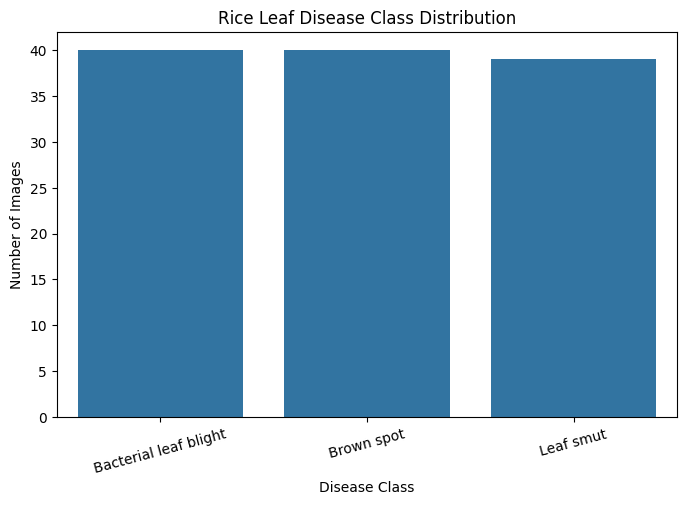

In [13]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=class_distribution,
    x="Disease",
    y="Number of Images"
)

plt.title("Rice Leaf Disease Class Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)

plt.show()

### Observation

The dataset contains three rice leaf disease classes: Bacterial Leaf Blight, Brown Spot, and Leaf Smut. Bacterial Leaf Blight and Brown Spot contain 40 images each, while Leaf Smut contains 39 images. Therefore, the dataset contains a total of 119 images.

The class distribution is almost balanced, with only one fewer image in the Leaf Smut class. Hence, there is no significant class imbalance in the dataset.

## Analyze Image Dimensions

In [14]:
image_dimensions = []

for class_name, path in class_paths.items():
    for file in os.listdir(path):
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            
            image_path = os.path.join(path, file)
            
            try:
                with Image.open(image_path) as img:
                    width, height = img.size
                    
                    image_dimensions.append({
                        "Disease": class_name,
                        "File": file,
                        "Width": width,
                        "Height": height
                    })
                    
            except Exception as e:
                print("Error reading:", image_path)
                print(e)

dimensions_df = pd.DataFrame(image_dimensions)

print("Total images analyzed:", len(dimensions_df))

dimensions_df.head()

Total images analyzed: 119


,Disease,File,Width,Height
0,Bacterial leaf blight,DSC_0365.JPG,3081,897
1,Bacterial leaf blight,DSC_0366.jpg,3081,897
2,Bacterial leaf blight,DSC_0367.JPG,3081,897
3,Bacterial leaf blight,DSC_0370.jpg,3081,897
4,Bacterial leaf blight,DSC_0372.JPG,3081,897


In [15]:
print("Unique image dimensions:")
print(
    dimensions_df[["Width", "Height"]]
    .drop_duplicates()
    .sort_values(["Width", "Height"])
    .to_string(index=False)
)

Unique image dimensions:
 Width  Height
   250     200
   286      92
   296      88
   301      71
   311     170
   316     127
   340      94
   359     168
   367      73
   376      80
   427     193
   456     124
   467     104
   503     174
   510     383
   537     216
   562     217
   565     233
   614     409
   617     244
   699     197
   741     291
   763     268
   765     224
   766     250
   768     514
   946     255
   948     211
   948     233
  1200     900
  1480     279
  1504     323
  1530     371
  3081     897


In [16]:
print("\nImage dimension statistics:")
print(dimensions_df[["Width", "Height"]].describe())


Image dimension statistics:
             Width      Height
count   119.000000  119.000000
mean   2383.638655  707.739496
std    1123.528972  311.657582
min     250.000000   71.000000
25%    1074.000000  377.000000
50%    3081.000000  897.000000
75%    3081.000000  897.000000
max    3081.000000  900.000000


### Observation

The images in the dataset have varying dimensions. Since deep learning models require inputs of a consistent size, the images need to be resized to a fixed dimension before model training.

Therefore, image resizing will be included as an important preprocessing step.

# Visualize Sample Images

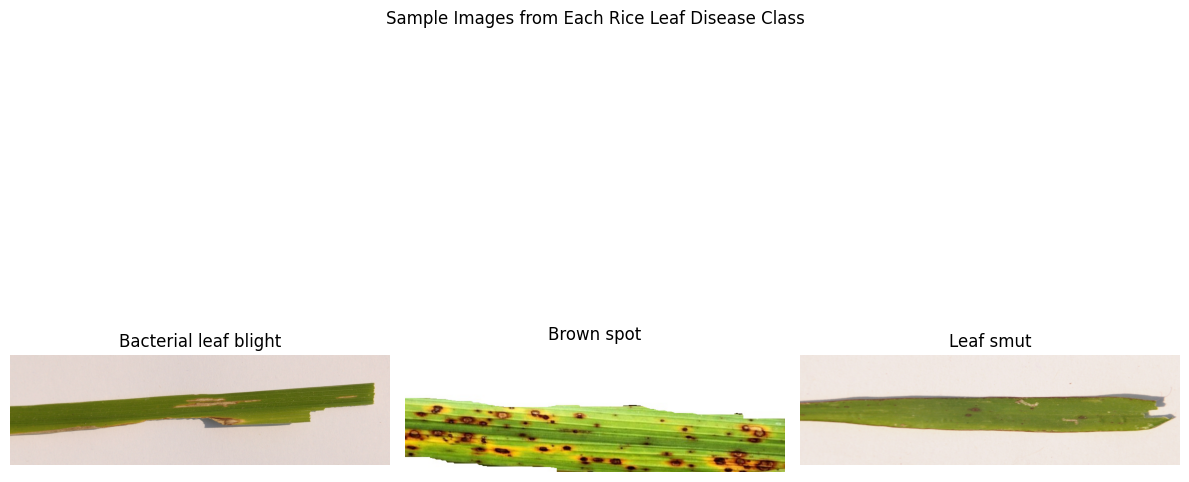

In [17]:
plt.figure(figsize=(12, 8))

for i, (class_name, path) in enumerate(class_paths.items()):
    
    image_files = [
        file for file in os.listdir(path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    
    # Select the first image from each class
    image_path = os.path.join(path, image_files[0])
    
    img = Image.open(image_path)
    
    plt.subplot(1, 3, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

plt.suptitle("Sample Images from Each Rice Leaf Disease Class")
plt.tight_layout()
plt.show()

### Observation

Sample images from all three disease classes were successfully loaded and visualized. The images show visible differences in the appearance and symptoms of the rice leaves across the disease classes.

These visual differences indicate that image-based deep learning techniques can be used to learn patterns associated with different rice leaf diseases.

# Display Multiple Images per Class

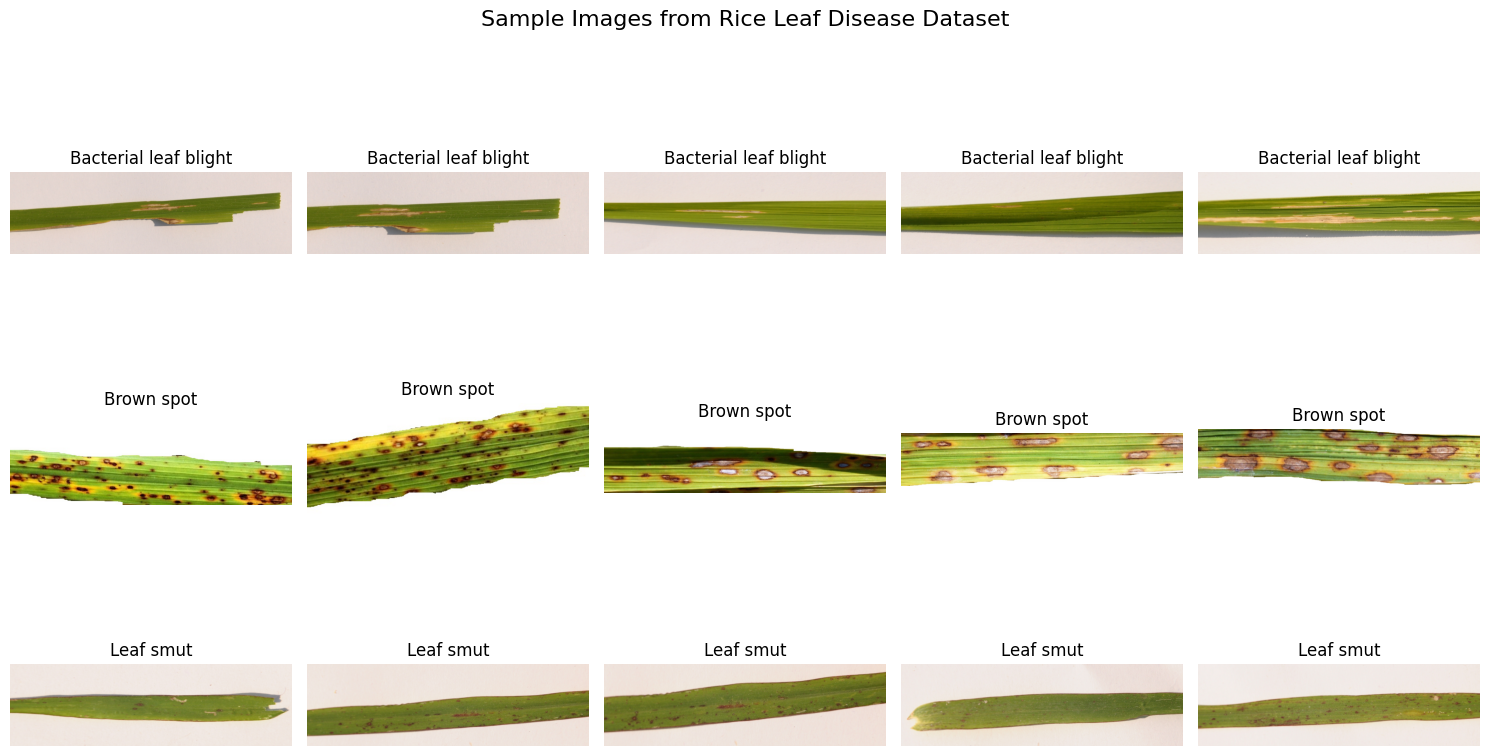

In [18]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for row, (class_name, path) in enumerate(class_paths.items()):
    
    image_files = [
        file for file in os.listdir(path)
        if file.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    
    # Take 5 images
    selected_images = image_files[:5]
    
    for col, file in enumerate(selected_images):
        
        image_path = os.path.join(path, file)
        img = Image.open(image_path)
        
        axes[row, col].imshow(img)
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.suptitle(
    "Sample Images from Rice Leaf Disease Dataset",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Observation

Multiple images from each disease class were visualized to understand the variation within the classes. Images belonging to the same disease show some variation in leaf appearance, orientation, background, and disease symptoms.

This variation is important because the model needs to learn disease-related features rather than memorizing a particular image. Data augmentation can later be investigated to improve the model's ability to handle such variations.

# Check for Corrupted Images

In [19]:
corrupted_images = []

for class_name, path in class_paths.items():
    
    for file in os.listdir(path):
        
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            
            image_path = os.path.join(path, file)
            
            try:
                with Image.open(image_path) as img:
                    img.verify()
                    
            except Exception as e:
                corrupted_images.append({
                    "Disease": class_name,
                    "File": file,
                    "Error": str(e)
                })

print("Total corrupted/unreadable images:", len(corrupted_images))

if len(corrupted_images) > 0:
    print("\nCorrupted images:")
    print(pd.DataFrame(corrupted_images))
else:
    print("No corrupted images found.")

Total corrupted/unreadable images: 0
No corrupted images found.


### Observation

All 119 images were successfully opened and verified without any corrupted or unreadable files. Therefore, no images had to be removed due to file corruption.

The dataset is suitable for the next stages of preprocessing and model development.

# Analyze Image Size Distribution

### Width distribution

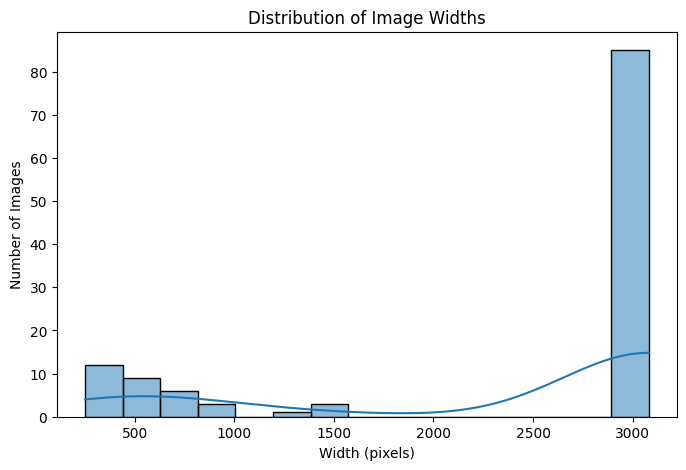

In [20]:
plt.figure(figsize=(8, 5))

sns.histplot(
    dimensions_df["Width"],
    bins=15,
    kde=True
)

plt.title("Distribution of Image Widths")
plt.xlabel("Width (pixels)")
plt.ylabel("Number of Images")

plt.show()

### Height distribution

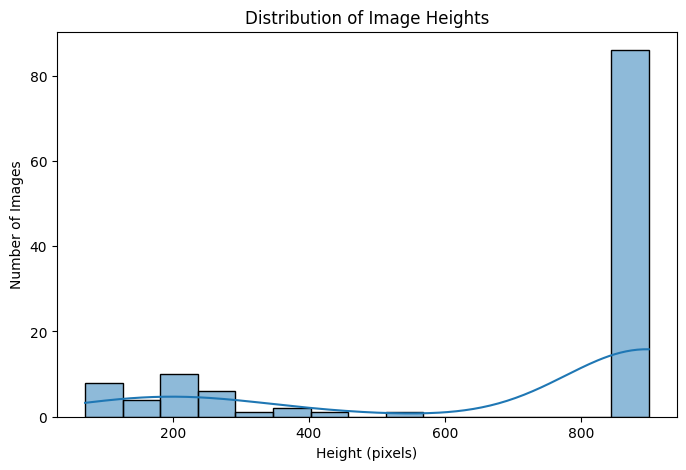

In [21]:
plt.figure(figsize=(8, 5))

sns.histplot(
    dimensions_df["Height"],
    bins=15,
    kde=True
)

plt.title("Distribution of Image Heights")
plt.xlabel("Height (pixels)")
plt.ylabel("Number of Images")

plt.show()

### Width vs Height

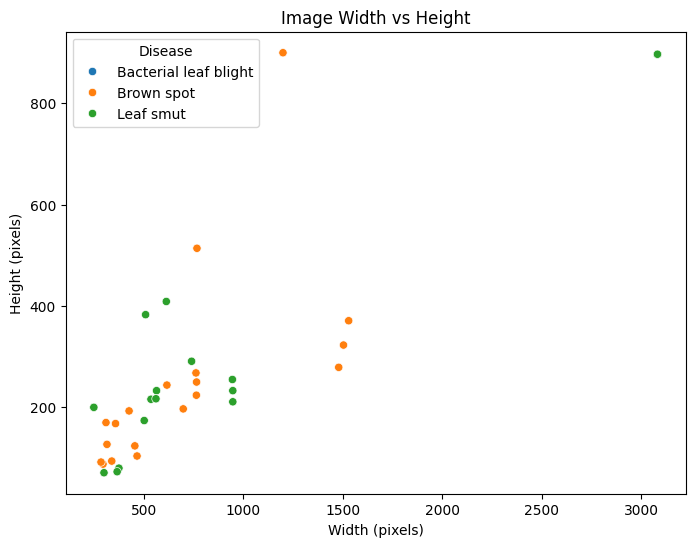

In [22]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=dimensions_df,
    x="Width",
    y="Height",
    hue="Disease"
)

plt.title("Image Width vs Height")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")

plt.show()

# Pixel Value Analysis

### Inspect one image

In [23]:
# Select one sample image
sample_class = "Brown spot"
sample_path = class_paths[sample_class]

sample_file = [
    file for file in os.listdir(sample_path)
    if file.lower().endswith((".jpg", ".jpeg", ".png"))
][0]

sample_image = Image.open(
    os.path.join(sample_path, sample_file)
).convert("RGB")

sample_array = np.array(sample_image)

print("Image shape:", sample_array.shape)
print("Minimum pixel value:", sample_array.min())
print("Maximum pixel value:", sample_array.max())
print("Mean pixel value:", sample_array.mean())

Image shape: (250, 766, 3)
Minimum pixel value: 0
Maximum pixel value: 255
Mean pixel value: 187.04962924281983


### Pixel-value distribution

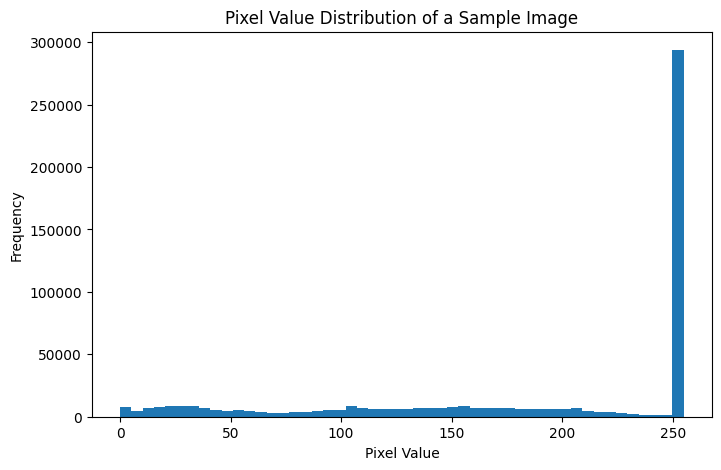

In [24]:
plt.figure(figsize=(8, 5))

plt.hist(
    sample_array.ravel(),
    bins=50
)

plt.title("Pixel Value Distribution of a Sample Image")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")

plt.show()

### Observation

The pixel-value analysis confirms that the images contain RGB pixel information with pixel values initially represented in the range of 0 to 255.

For efficient neural network training, the pixel values will be normalized to a range between 0 and 1 during preprocessing.

# Data Preprocessing

### Set image size and create arrays

In [25]:
# Define the image size
IMG_SIZE = 128

# Create empty lists
images = []
labels = []

# Numerical labels for each disease
label_map = {
    "Bacterial leaf blight": 0,
    "Brown spot": 1,
    "Leaf smut": 2
}

# Load and preprocess images
for class_name, path in class_paths.items():

    for file in os.listdir(path):

        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            image_path = os.path.join(path, file)

            # Open image and convert to RGB
            img = Image.open(image_path).convert("RGB")

            # Resize image
            img = img.resize((IMG_SIZE, IMG_SIZE))

            # Convert image to NumPy array
            img_array = np.array(img)

            # Store image and label
            images.append(img_array)
            labels.append(label_map[class_name])

# Convert lists into NumPy arrays
X = np.array(images)
y = np.array(labels)

print("Image data shape:", X.shape)
print("Label data shape:", y.shape)

Image data shape: (119, 128, 128, 3)
Label data shape: (119,)


### Normalize pixel values

In [26]:
# Normalize pixel values from 0-255 to 0-1
X = X.astype("float32") / 255.0

print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


### Verify the labels

In [27]:
print("Label mapping:")
print(label_map)

print("\nUnique labels:")
print(np.unique(y))

print("\nNumber of images per label:")
print(pd.Series(y).value_counts().sort_index())

Label mapping:
{'Bacterial leaf blight': 0, 'Brown spot': 1, 'Leaf smut': 2}

Unique labels:
[0 1 2]

Number of images per label:
0    40
1    40
2    39
Name: count, dtype: int64


### Observation

The rice leaf images were successfully preprocessed by converting them into RGB format and resizing them to a uniform size of 128 × 128 pixels. This ensures that all images have the same dimensions and can be provided as input to the CNN model.

The pixel values were normalized from the original range of 0–255 to a range of 0–1. This scaling helps provide suitable numerical input for neural network training.

A total of 119 valid images were processed, with 40 images of Bacterial Leaf Blight, 40 images of Brown Spot, and 39 images of Leaf Smut.

# Train/Test Split

### Split the data

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training images:", X_train.shape[0])
print("Testing images:", X_test.shape[0])

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training images: 95
Testing images: 24

Training data shape: (95, 128, 128, 3)
Testing data shape: (24, 128, 128, 3)


### Check class distribution after splitting

In [29]:
print("Training class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training class distribution:
0    32
1    32
2    31
Name: count, dtype: int64

Testing class distribution:
0    8
1    8
2    8
Name: count, dtype: int64


### Observation

The dataset was divided into training and testing sets using an 80:20 split. Since the dataset contains only 119 images, a stratified split was used to maintain a similar proportion of all three disease classes in both the training and testing sets.

Approximately 80% of the images are used for training and 20% are reserved for testing. The testing data will remain unseen during model training and will be used to evaluate the model's performance on new images.

# Build the Baseline CNN

### Import TensorFlow/Keras

In [30]:
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### Create the Baseline CNN

In [31]:
cnn_model = Sequential([
    
    # First convolution block
    Conv2D(32, (3, 3), activation="relu", input_shape=(128, 128, 3)),
    MaxPooling2D((2, 2)),
    
    # Second convolution block
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    
    # Third convolution block
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),
    
    # Classification layers
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    
    # 3 disease classes
    Dense(3, activation="softmax")
])

cnn_model.summary()

site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

### Compile the CNN

In [32]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


### Train the Baseline CNN

In [33]:
history = cnn_model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.4079 - loss: 1.2912 - val_accuracy: 0.5263 - val_loss: 1.0661
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.3289 - loss: 1.1105 - val_accuracy: 0.3684 - val_loss: 1.0847
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 5s 950ms/step - accuracy: 0.4211 - loss: 1.0756 - val_accuracy: 0.3684 - val_loss: 1.0505
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.3947 - loss: 1.0282 - val_accuracy: 0.6316 - val_loss: 0.9480
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.4474 - loss: 1.0166 - val_accuracy: 0.6316 - val_loss: 0.8908
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.6053 - loss: 0.9007 - val_accuracy: 0.6842 - val_loss: 0.8200
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.6711 - loss: 0.8308 - val_accuracy: 0.6316 - val_loss: 0.7428
Epoch 8/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.6579 - loss: 0.7672 - val_accuracy: 0.6842 - val_loss: 0.6976
Epoch 9/20
5

### Plot Training & Validation Accuracy

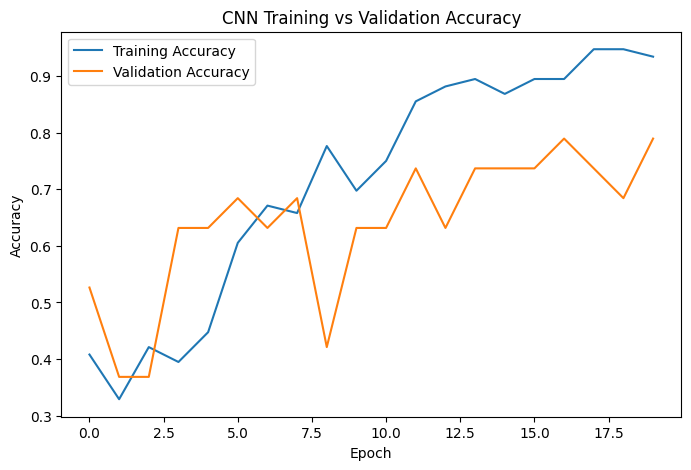

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

### Plot Training & Validation Loss

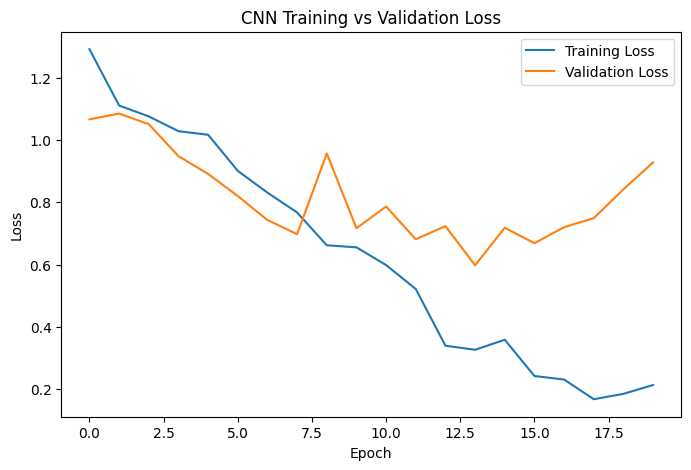

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

### Observation

The training and validation accuracy/loss curves were plotted to understand the learning behavior of the baseline CNN.

The accuracy curves show how the model's classification performance changes across epochs, while the loss curves show how the prediction error changes during training.

These curves will help identify whether the model is learning effectively and whether there are signs of overfitting or underfitting.

### Evaluate the CNN on Test Data

In [36]:
test_loss, test_accuracy = cnn_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: 1.1673847436904907
Test Accuracy: 0.6666666865348816


### Generate Predictions

In [37]:
y_pred_prob = cnn_model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Predictions generated successfully!")
print("Predicted labels:", y_pred)
print("Actual labels:   ", y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 961ms/step
Predictions generated successfully!
Predicted labels: [2 1 2 2 0 1 1 1 0 0 1 1 0 2 1 0 0 0 1 1 1 0 0 1]
Actual labels:    [2 1 2 1 0 2 0 2 0 1 1 1 0 2 1 2 0 0 2 2 1 0 0 1]


### Classification Report

In [38]:
class_names = [
    "Bacterial leaf blight",
    "Brown spot",
    "Leaf smut"
]

print("Classification Report:\n")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names
    )
)

Classification Report:

                       precision    recall  f1-score   support

Bacterial leaf blight       0.78      0.88      0.82         8
           Brown spot       0.55      0.75      0.63         8
            Leaf smut       0.75      0.38      0.50         8

             accuracy                           0.67        24
            macro avg       0.69      0.67      0.65        24
         weighted avg       0.69      0.67      0.65        24



### Confusion Matrix

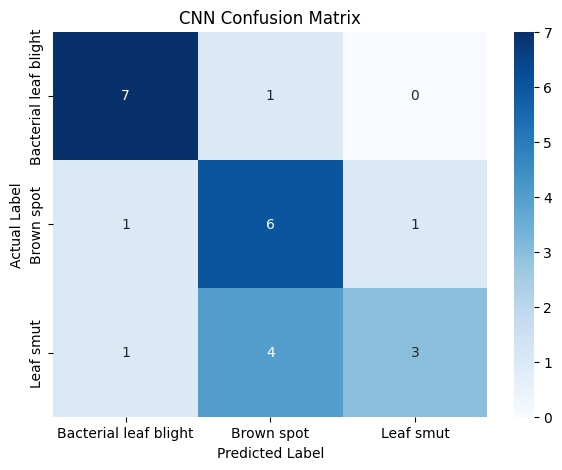

In [39]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

### Observation

The baseline CNN was evaluated using the unseen test dataset. The classification report provides precision, recall, F1-score, and support for each rice leaf disease class.

The confusion matrix shows the number of correct and incorrect predictions for each disease class. The diagonal values represent correctly classified images, while the off-diagonal values represent misclassifications.

The baseline CNN provides a starting point for comparing the effect of data augmentation and other modeling techniques in the next stages of the project.

# Data Augmentation

### Create Data Augmentation Layer

In [40]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomZoom, RandomTranslation

data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1),
    RandomTranslation(0.1, 0.1)
])

print("Data augmentation pipeline created successfully!")

Data augmentation pipeline created successfully!


### Visualize Augmented Images

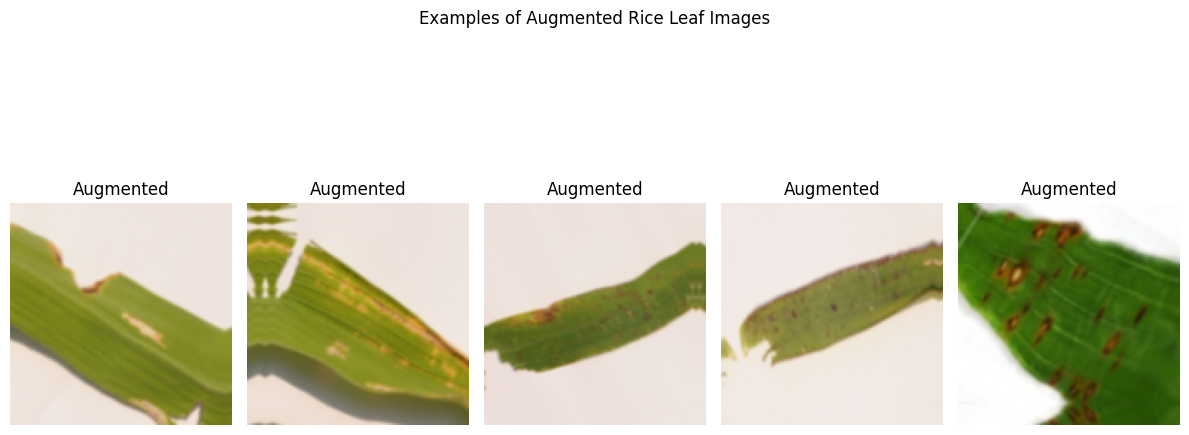

In [41]:
sample_images = X_train[:5]

plt.figure(figsize=(12, 6))

for i in range(5):
    augmented_image = data_augmentation(
        np.expand_dims(sample_images[i], axis=0),
        training=True
    )[0]

    plt.subplot(1, 5, i + 1)
    plt.imshow(augmented_image.numpy())
    plt.axis("off")
    plt.title("Augmented")

plt.suptitle("Examples of Augmented Rice Leaf Images")
plt.tight_layout()
plt.show()

### Observation

Data augmentation successfully generated modified versions of the training images. The applied transformations include horizontal flipping, rotation, zooming, and translation.

These transformations introduce additional variation into the training data without requiring new original images. This can help the CNN learn more robust disease-related features and reduce the risk of overfitting on the small dataset.

## Build the Augmented CNN

In [42]:
augmented_cnn = Sequential([
    data_augmentation,

    Conv2D(32, (3, 3), activation="relu", input_shape=(128, 128, 3)),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(3, activation="softmax")
])

augmented_cnn.summary()

site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)            │ (1, 128, 128, 3)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (1, 126, 126, 32)           │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (1, 63, 63, 32)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (1, 61, 61, 64)             │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (1, 30, 30, 64)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (1, 28, 28, 128)            │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (1, 14, 14, 128)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (1, 25088)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (1, 128)                    │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (1, 128)                    │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (1, 3)                      │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

### Compile the Augmented CNN

In [43]:
augmented_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Augmented CNN model compiled successfully!")

Augmented CNN model compiled successfully!


### Train the Augmented CNN

In [44]:
augmented_history = augmented_cnn.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.3026 - loss: 1.5332 - val_accuracy: 0.2105 - val_loss: 1.1508
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.3553 - loss: 1.1098 - val_accuracy: 0.3684 - val_loss: 1.0980
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.3158 - loss: 1.1489 - val_accuracy: 0.3684 - val_loss: 1.0732
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.4342 - loss: 1.0860 - val_accuracy: 0.6842 - val_loss: 1.0702
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.5000 - loss: 1.0769 - val_accuracy: 0.5789 - val_loss: 1.0508
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.4211 - loss: 1.0638 - val_accuracy: 0.6842 - val_loss: 0.9380
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 7s 1s/step - accuracy: 0.5263 - loss: 0.9843 - val_accuracy: 0.4737 - val_loss: 0.9642
Epoch 8/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 8s 2s/step - accuracy: 0.3816 - loss: 1.0480 - val_accuracy: 0.6842 - val_loss: 0.8812
Epoch 9/20
5/5 

### Plot Augmented CNN Accuracy

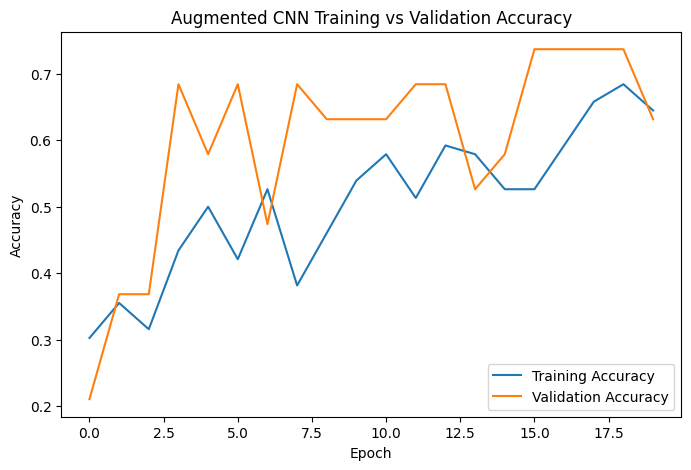

In [45]:
plt.figure(figsize=(8, 5))

plt.plot(
    augmented_history.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    augmented_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Augmented CNN Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

### Plot Augmented CNN Loss

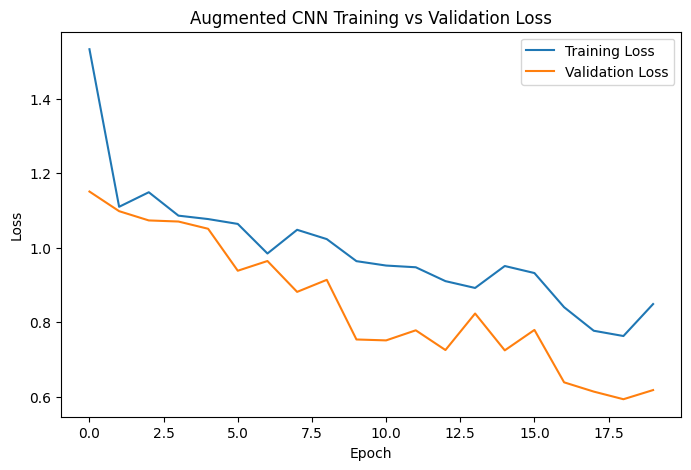

In [46]:
plt.figure(figsize=(8, 5))

plt.plot(
    augmented_history.history["loss"],
    label="Training Loss"
)
plt.plot(
    augmented_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Augmented CNN Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

### Observation

The augmented CNN was trained using image augmentation techniques such as horizontal flipping, rotation, zooming, and translation.

The training and validation accuracy curves, along with the loss curves, were plotted to analyze the learning behavior of the augmented model.

Data augmentation increases the variation available to the model during training and can help improve generalization on unseen images. The actual performance improvement will be determined by comparing the augmented CNN with the baseline CNN on the same test dataset.

### Evaluate the Augmented CNN

In [47]:
aug_test_loss, aug_test_accuracy = augmented_cnn.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Augmented CNN Test Loss:", aug_test_loss)
print("Augmented CNN Test Accuracy:", aug_test_accuracy)

Augmented CNN Test Loss: 0.584549069404602
Augmented CNN Test Accuracy: 0.6666666865348816


### Generate Augmented CNN Predictions

In [48]:
aug_y_pred_prob = augmented_cnn.predict(X_test)

aug_y_pred = np.argmax(aug_y_pred_prob, axis=1)

print("Augmented CNN predictions generated successfully!")
print("Predicted labels:", aug_y_pred)
print("Actual labels:   ", y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   
Augmented CNN predictions generated successfully!
Predicted labels: [0 1 2 0 0 1 0 1 0 0 1 0 0 2 1 0 0 0 2 2 1 0 0 0]
Actual labels:    [2 1 2 1 0 2 0 2 0 1 1 1 0 2 1 2 0 0 2 2 1 0 0 1]


### Classification Report for Augmented CNN

In [49]:
print("Augmented CNN Classification Report:\n")

print(
    classification_report(
        y_test,
        aug_y_pred,
        target_names=class_names
    )
)

Augmented CNN Classification Report:

                       precision    recall  f1-score   support

Bacterial leaf blight       0.57      1.00      0.73         8
           Brown spot       0.67      0.50      0.57         8
            Leaf smut       1.00      0.50      0.67         8

             accuracy                           0.67        24
            macro avg       0.75      0.67      0.66        24
         weighted avg       0.75      0.67      0.66        24



### Confusion Matrix for Augmented CNN

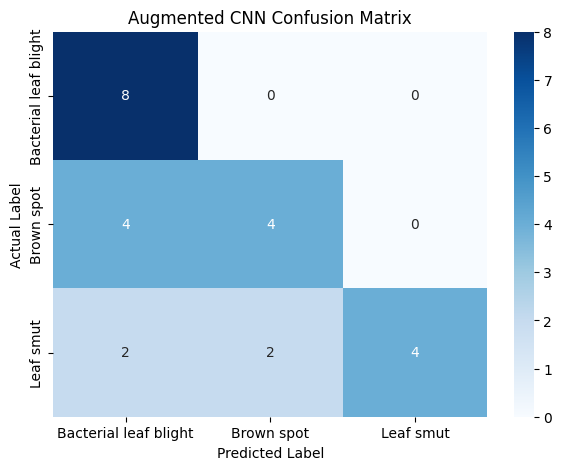

In [50]:
aug_cm = confusion_matrix(y_test, aug_y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    aug_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Augmented CNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

### Observation

The Augmented CNN was evaluated on the same unseen test dataset used for the baseline CNN.

The classification report provides the precision, recall, F1-score, and support for each disease class, while the confusion matrix shows the correct and incorrect predictions for each class.

The performance of the Augmented CNN can now be compared with the baseline CNN to determine whether data augmentation improved the model's ability to generalize to unseen images.

# Compare Model Accuracy

In [51]:
model_comparison = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "Augmented CNN"
    ],
    "Test Accuracy": [
        test_accuracy,
        aug_test_accuracy
    ]
})

model_comparison

,Model,Test Accuracy
0,Baseline CNN,0.666667
1,Augmented CNN,0.666667


### Visualize Model Comparison

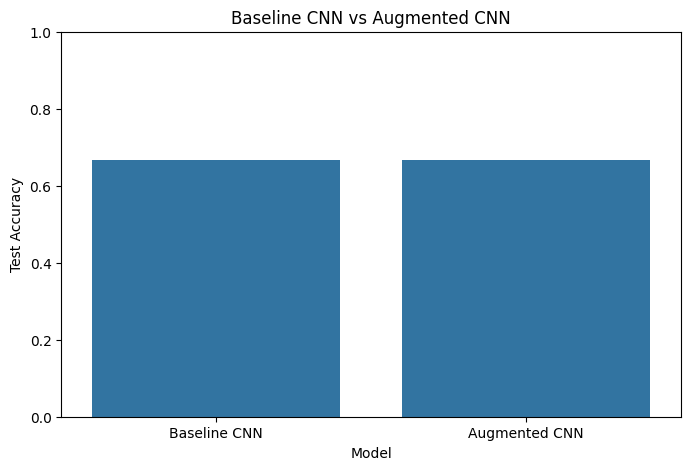

In [52]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Test Accuracy"
)

plt.title("Baseline CNN vs Augmented CNN")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.show()

### Observation

The test accuracy of the Baseline CNN and Augmented CNN was compared using a table and bar chart.

The comparison helps determine whether data augmentation improved the model's performance on unseen test images.

The model with the higher test accuracy provides better performance on this dataset. However, accuracy alone should not be considered sufficient; the classification report and confusion matrix should also be considered when selecting the final model.

# Transfer Learning (MobileNetV2)

In [53]:
from tensorflow.keras.applications import MobileNetV2

print("MobileNetV2 imported successfully!")

MobileNetV2 imported successfully!


## Load MobileNetV2 Base Model

In [54]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)

print("MobileNetV2 base model loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 base model loaded successfully!


### Freeze the Pre-trained Layers

In [55]:
base_model.trainable = False

print("MobileNetV2 base layers frozen.")
print("Trainable:", base_model.trainable)

MobileNetV2 base layers frozen.
Trainable: False


### Build the MobileNetV2 Classifier

In [56]:
transfer_model = Sequential([
    base_model,
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(3, activation="softmax")
])

transfer_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128 (Functional)    │ (None, 4, 4, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_2 (Flatten)                  │ (None, 20480)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │       2,621,568 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,879,939 (18.62 MB)

 Trainable params: 2,621,955 (10.00 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Compile the Transfer Learning Model

In [57]:
transfer_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Transfer learning model compiled successfully!")

Transfer learning model compiled successfully!


## Train the Transfer Learning Model

In [58]:
transfer_history = transfer_model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 23s 2s/step - accuracy: 0.3289 - loss: 7.1751 - val_accuracy: 0.5789 - val_loss: 5.9855
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 485ms/step - accuracy: 0.7237 - loss: 2.5219 - val_accuracy: 0.8421 - val_loss: 0.3876
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 694ms/step - accuracy: 0.8421 - loss: 0.9921 - val_accuracy: 0.8421 - val_loss: 1.7072
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 500ms/step - accuracy: 0.9079 - loss: 0.2010 - val_accuracy: 0.8421 - val_loss: 1.0531
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 3s 526ms/step - accuracy: 0.9474 - loss: 0.2025 - val_accuracy: 0.8421 - val_loss: 0.3744
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 5s 552ms/step - accuracy: 1.0000 - loss: 0.0400 - val_accuracy: 0.8421 - val_loss: 0.2660
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 416ms/step - accuracy: 0.9737 - loss: 0.1101 - val_accuracy: 0.8421 - val_loss: 0.3448
Epoch 8/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 514ms/step - accuracy: 0.9605 - loss: 0.1369 - val_accuracy: 0.8421 - val_loss: 0

## Evaluate MobileNetV2 on Test Data

In [59]:
transfer_test_loss, transfer_test_accuracy = transfer_model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Transfer Learning Test Loss:", transfer_test_loss)
print("Transfer Learning Test Accuracy:", transfer_test_accuracy)

Transfer Learning Test Loss: 0.5175715684890747
Transfer Learning Test Accuracy: 0.8333333134651184


## Generate Transfer Learning Predictions

In [60]:
transfer_y_pred_prob = transfer_model.predict(X_test)

transfer_y_pred = np.argmax(transfer_y_pred_prob, axis=1)

print("Transfer Learning predictions generated successfully!")
print("Predicted labels:", transfer_y_pred)
print("Actual labels:   ", y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Transfer Learning predictions generated successfully!
Predicted labels: [2 1 2 0 0 2 0 2 0 1 1 2 0 2 1 0 0 0 2 1 1 0 0 1]
Actual labels:    [2 1 2 1 0 2 0 2 0 1 1 1 0 2 1 2 0 0 2 2 1 0 0 1]


### Classification Report of Transfer Learning Predictions

In [62]:
print("Transfer Learning Classification Report:\n")

print(
    classification_report(
        y_test,
        transfer_y_pred,
        target_names=class_names
    )
)

Transfer Learning Classification Report:

                       precision    recall  f1-score   support

Bacterial leaf blight       0.80      1.00      0.89         8
           Brown spot       0.86      0.75      0.80         8
            Leaf smut       0.86      0.75      0.80         8

             accuracy                           0.83        24
            macro avg       0.84      0.83      0.83        24
         weighted avg       0.84      0.83      0.83        24



### Confusion Matrix for Transfer Learning

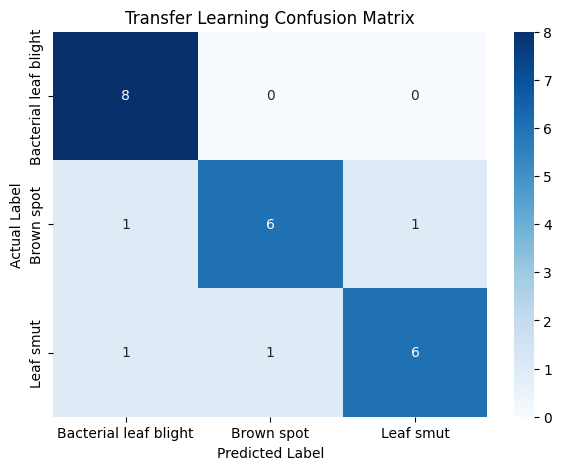

In [63]:
transfer_cm = confusion_matrix(y_test, transfer_y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    transfer_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Transfer Learning Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

### Observation

The MobileNetV2 transfer learning model was evaluated using the same unseen test dataset as the Baseline CNN and Augmented CNN.

The classification report provides precision, recall, F1-score, and support for each rice leaf disease class. The confusion matrix shows the correctly classified and misclassified images for each class.

Transfer learning provides an additional modeling approach for comparison and is particularly useful for this small dataset because the MobileNetV2 base model was pre-trained on a large image dataset.

# Final Model Comparison

In [65]:
final_model_comparison = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "Augmented CNN",
        "MobileNetV2 Transfer Learning"
    ],
    "Test Accuracy": [
        test_accuracy,
        aug_test_accuracy,
        transfer_test_accuracy
    ]
})

final_model_comparison

,Model,Test Accuracy
0,Baseline CNN,0.666667
1,Augmented CNN,0.666667
2,MobileNetV2 Transfer Learning,0.833333


## Visualize Final Model Comparison

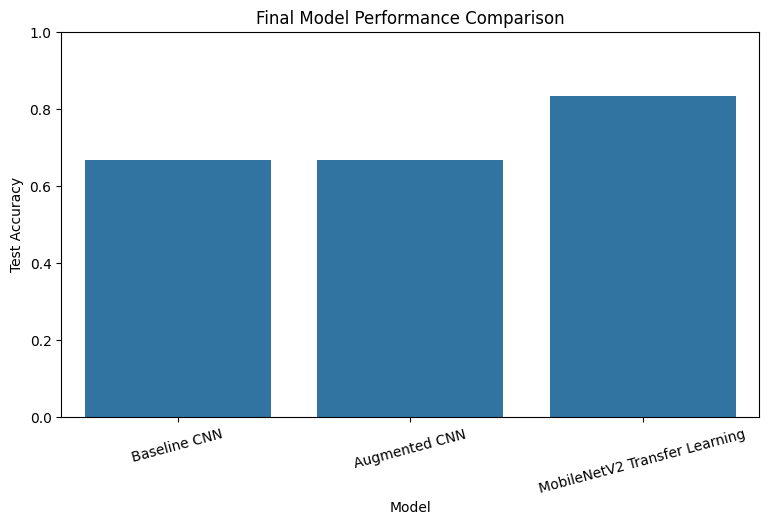

In [66]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=final_model_comparison,
    x="Model",
    y="Test Accuracy"
)

plt.title("Final Model Performance Comparison")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

### Observation

The final comparison shows that the MobileNetV2 Transfer Learning model achieved the highest test accuracy of 83.33%.

The Baseline CNN and Augmented CNN both achieved a test accuracy of 66.67%. In comparison, MobileNetV2 improved the test accuracy by approximately 16.67 percentage points.

Therefore, MobileNetV2 Transfer Learning is the best-performing model among the three models evaluated on the available test dataset.

However, the dataset contains only 119 images, so the results should be interpreted with caution. Additional data and further validation would be beneficial before deploying the model in a real-world production environment.

# Final Model Selection

In [67]:
best_model = transfer_model
best_model_name = "MobileNetV2 Transfer Learning"

print("Best Model:", best_model_name)
print("Best Accuracy:", transfer_test_accuracy)

Best Model: MobileNetV2 Transfer Learning
Best Accuracy: 0.8333333134651184


## Select a Test Image

Actual Disease: Leaf smut


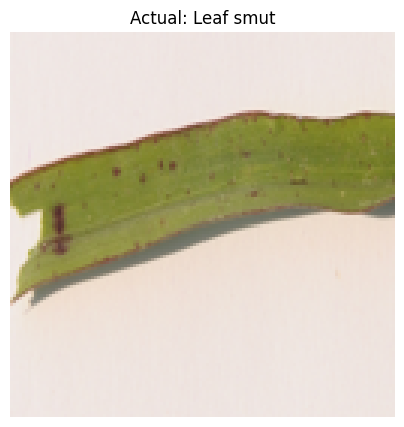

In [68]:
sample_index = 0

sample_image = X_test[sample_index]
actual_label = y_test[sample_index]

print("Actual Disease:", class_names[actual_label])

plt.figure(figsize=(5, 5))
plt.imshow(sample_image)
plt.title(f"Actual: {class_names[actual_label]}")
plt.axis("off")
plt.show()

## Predict the Disease

In [69]:
sample_input = np.expand_dims(sample_image, axis=0)

prediction_probabilities = best_model.predict(sample_input)

predicted_label = np.argmax(prediction_probabilities, axis=1)[0]
predicted_disease = class_names[predicted_label]
confidence = prediction_probabilities[0][predicted_label]

print("Actual Disease:", class_names[actual_label])
print("Predicted Disease:", predicted_disease)
print("Prediction Confidence:", confidence)

1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step
Actual Disease: Leaf smut
Predicted Disease: Leaf smut
Prediction Confidence: 0.93620956


### Observation

The selected MobileNetV2 Transfer Learning model was used to classify an unseen rice leaf image.

The model generated a predicted disease class along with a confidence score. The predicted class can be compared with the actual class of the test image to determine whether the individual prediction was correct.

This demonstrates how the trained model can be used for rice leaf disease classification on an unseen image.

# Data Augmentation Report


Data augmentation was applied to the training images to increase the variation available to the CNN during training.

The following augmentation techniques were used:

- **Horizontal Flipping:** Creates a horizontally flipped version of an image.
- **Rotation:** Rotates the image slightly to introduce variation in leaf orientation.
- **Zooming:** Changes the image scale to help the model handle different distances and sizes.
- **Translation:** Shifts the image horizontally and vertically to introduce positional variation.

Data augmentation was applied only to the training data, while the original test data was kept unchanged for fair evaluation.

The Baseline CNN achieved a test accuracy of 66.67%, while the Augmented CNN also achieved 66.67% on the available test dataset. Therefore, data augmentation did not improve the test accuracy in this particular experiment.

However, augmentation remains useful for increasing training variation and may provide greater benefits when a larger dataset is available.

# Challenges Report

## Challenges Report

### 1. Small Dataset Size

The available dataset contains only 119 valid images across three disease classes. A small dataset can make deep learning models more prone to overfitting and can limit their ability to learn highly generalizable features.

### 2. Difference in Expected and Available Images

The project specification states that the dataset contains 120 images with 40 images in each class. However, after extracting and verifying the provided dataset, 119 valid images were found: 40 Bacterial Leaf Blight, 40 Brown Spot, and 39 Leaf Smut.

No artificial image duplication was performed. The available images were used as provided.

### 3. Different Image Dimensions

The original images have different dimensions. Since CNN models require a consistent input size, all images were resized to 128 × 128 pixels during preprocessing.

### 4. Variation in Images

Images within the same disease class show differences in orientation, background, leaf appearance, and disease symptoms. The model therefore needs to learn disease-related features rather than memorize individual images.

### 5. Data Augmentation

Data augmentation was investigated using flipping, rotation, zooming, and translation. In this experiment, augmentation did not improve the final test accuracy compared with the baseline CNN.

### 6. Limited Test Data

Because the complete dataset contains only 119 images, the test set is also relatively small. Therefore, model accuracy can vary depending on the train-test split, and additional data would be useful for more reliable evaluation.

### 7. Model Selection

Three approaches were compared: Baseline CNN, Augmented CNN, and MobileNetV2 Transfer Learning. MobileNetV2 achieved the highest test accuracy of 83.33% and was selected as the best-performing model for this experiment.

## Model Comparison & Production Recommendation



Three modeling approaches were evaluated for rice leaf disease classification:

| Model | Test Accuracy |
|---|---:|
| Baseline CNN | 66.67% |
| Augmented CNN | 66.67% |
| MobileNetV2 Transfer Learning | 83.33% |

### Comparison

The Baseline CNN achieved a test accuracy of 66.67%. The Augmented CNN also achieved 66.67%, indicating that the selected augmentation techniques did not improve test accuracy in this experiment.

MobileNetV2 Transfer Learning achieved the highest test accuracy of 83.33%. It outperformed both custom CNN models by approximately 16.67 percentage points.

### Recommended Model

Based on the test accuracy obtained in this experiment, **MobileNetV2 Transfer Learning** is selected as the best-performing model.

MobileNetV2 is particularly suitable for this dataset because the available dataset is small and the model can utilize features learned from a large image dataset through transfer learning.

However, the dataset contains only 119 images and the test set is small. Therefore, the 83.33% accuracy should not be considered sufficient evidence for real-world production deployment. A larger and more diverse dataset, additional validation, and testing on real-world rice leaf images would be recommended before production use.

## Final Conclusion

This project developed a deep learning-based system for classifying rice leaf diseases into three categories: Bacterial Leaf Blight, Brown Spot, and Leaf Smut.

The dataset was analyzed and preprocessed by resizing the images to 128 × 128 pixels and normalizing pixel values to the range 0–1. The dataset contained 119 valid images after verification.

Three modeling approaches were evaluated:

- Baseline CNN — 66.67% test accuracy
- Augmented CNN — 66.67% test accuracy
- MobileNetV2 Transfer Learning — 83.33% test accuracy

Among the evaluated models, MobileNetV2 Transfer Learning achieved the highest test accuracy and was selected as the best-performing model for this experiment.

Data augmentation was also investigated using flipping, rotation, zooming, and translation. Although augmentation did not improve the test accuracy in this experiment, it provides additional variation during training and may be more beneficial with a larger dataset.

Overall, the project demonstrates that transfer learning can be an effective approach for image classification when the available dataset is relatively small. For future improvement, a larger and more diverse dataset, additional validation, and testing on real-world images would be recommended before production deployment.